# Week 6: Integrative Capstone Project

## Project Title
**Retail Sales Analysis and Customer Segmentation Using Python**

### Objective
The objective of this project is to analyze retail sales data, identify sales trends, predict sales using machine learning, and segment customers using clustering techniques.

### Tools and Technologies
- Python
- Jupyter Notebook
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn

### Project Workflow
1. Data Loading and Inspection
2. Data Preprocessing
3. Exploratory Data Analysis (EDA)
4. Feature Engineering
5. Supervised Machine Learning
6. Customer Segmentation using K-Means
7. Model Evaluation
8. Business Insights and Recommendations
9. Final Report Preparation

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")
print("Current working directory:", os.getcwd())
print("\nFiles available in the current directory:")
print(os.listdir())

Libraries imported successfully!
Current working directory: C:\Users\Ayush\YuvaIntern_Data_Science\Notebooks

Files available in the current directory:
['.ipynb_checkpoints', 'online_retail_cleaned.csv', 'Task1_Data_Cleaning.ipynb', 'Task2_EDA_Visualization.ipynb', 'Task3_Clustering_Analysis.ipynb', 'Task4_Supervised_Learning.ipynb', 'task5_actual_vs_predicted.png', 'task5_ann_evaluation_results.csv', 'Task5_Deep_Learning_ANN.ipynb', 'task5_training_loss.png', 'YuvaIntern-Week6-Capstone.ipynb']


## 1. Data Loading and Initial Inspection

In this step, we load the cleaned online retail dataset using Pandas.
We inspect the dataset's dimensions, column names, data types, and sample records to understand its structure before performing further analysis.

In [2]:
# Load the cleaned dataset

file_path = "online_retail_cleaned.csv"

if os.path.exists(file_path):
    df = pd.read_csv(file_path)

    print("Dataset loaded successfully!")
    print("Dataset shape:", df.shape)

    print("\nFirst 5 rows:")
    display(df.head())

    print("\nColumn names:")
    print(df.columns.tolist())

else:
    print("Dataset not found in the current directory.")
    print("Current directory:", os.getcwd())
    print("Please check the file location.")

Dataset loaded successfully!
Dataset shape: (536641, 8)

First 5 rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01-12-2010 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01-12-2010 08:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01-12-2010 08:26,3.39,17850.0,United Kingdom



Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [5]:
# Inspect data types and dataset information

print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include="all").T)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 536641 entries, 0 to 536640
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    536641 non-null  object 
 1   StockCode    536641 non-null  object 
 2   Description  535187 non-null  object 
 3   Quantity     536641 non-null  int64  
 4   InvoiceDate  536641 non-null  object 
 5   UnitPrice    536641 non-null  float64
 6   CustomerID   401604 non-null  float64
 7   Country      536641 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 32.8+ MB

Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
InvoiceNo,536641,25900,573585,1114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,536641,4070,85123A,2301,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,535187,4223,WHITE HANGING HEART T-LIGHT HOLDER,2357,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,536641.0,NaN,NaN,NaN,9.620029,219.130156,-80995.0,1.0,3.0,10.0,80995.0
InvoiceDate,536641,23260,31-10-2011 14:41,1114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
UnitPrice,536641.0,NaN,NaN,NaN,4.632656,97.233118,-11062.06,1.25,2.08,4.13,38970.0
CustomerID,401604.0,NaN,NaN,NaN,15281.160818,1714.006089,12346.0,13939.0,15145.0,16784.0,18287.0
Country,536641,38,United Kingdom,490300,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Data Quality Assessment

In this step, we assess the quality of the dataset by checking missing values, duplicate records, and data types.

This assessment helps identify data quality issues before performing exploratory data analysis and machine learning.

In [6]:
# Check missing values in each column

missing_values = df.isnull().sum()

missing_report = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage (%)": (missing_values / len(df) * 100).round(2)
})

display(missing_report.sort_values(
    by="Missing Values",
    ascending=False
))

print("Total missing values:", df.isnull().sum().sum())

,Missing Values,Missing Percentage (%)
CustomerID,135037,25.16
Description,1454,0.27
StockCode,0,0.00
InvoiceNo,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
Country,0,0.00


Total missing values: 136491


In [7]:
# Check duplicate records

duplicate_count = df.duplicated().sum()

print("Total rows:", len(df))
print("Duplicate rows:", duplicate_count)
print("Unique rows:", len(df) - duplicate_count)

Total rows: 536641
Duplicate rows: 0
Unique rows: 536641


In [8]:
# Check column data types

data_type_report = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Unique Values": df.nunique(dropna=True).values
})

display(data_type_report)

,Column,Data Type,Unique Values
0,InvoiceNo,object,25900
1,StockCode,object,4070
2,Description,object,4223
3,Quantity,int64,722
4,InvoiceDate,object,23260
5,UnitPrice,float64,1630
6,CustomerID,float64,4372
7,Country,object,38


### Initial Data Quality Findings

The dataset was examined for missing values, duplicate records, and column data types.

The results of these checks will guide any additional preprocessing required before exploratory data analysis. No records are removed at this stage.

## 3. Data Preprocessing and Feature Engineering

In this step, we prepare the dataset for exploratory data analysis and machine learning.

The process includes:
- Creating a working copy of the dataset
- Converting date columns into datetime format
- Handling invalid values where applicable
- Creating a TotalSales feature
- Extracting useful date-related features

In [9]:
# Create a separate working copy

df_processed = df.copy()

print("Original dataset shape:", df.shape)
print("Working dataset shape:", df_processed.shape)

Original dataset shape: (536641, 8)
Working dataset shape: (536641, 8)


In [10]:
# Display column names

print("Available columns:")
for column in df_processed.columns:
    print("-", column)

Available columns:
- InvoiceNo
- StockCode
- Description
- Quantity
- InvoiceDate
- UnitPrice
- CustomerID
- Country


In [11]:
# Convert InvoiceDate to datetime format

if "InvoiceDate" in df_processed.columns:
    df_processed["InvoiceDate"] = pd.to_datetime(
        df_processed["InvoiceDate"],
        errors="coerce"
    )
    print("InvoiceDate converted to datetime format.")
else:
    print("InvoiceDate column not found. Check the column names.")

InvoiceDate converted to datetime format.


In [12]:
# Create TotalSales feature if required columns exist

required_columns = ["Quantity", "UnitPrice"]

if all(column in df_processed.columns for column in required_columns):
    df_processed["Quantity"] = pd.to_numeric(
        df_processed["Quantity"], errors="coerce"
    )
    df_processed["UnitPrice"] = pd.to_numeric(
        df_processed["UnitPrice"], errors="coerce"
    )

    df_processed["TotalSales"] = (
        df_processed["Quantity"] * df_processed["UnitPrice"]
    )

    print("TotalSales feature created successfully.")
    display(df_processed[
        ["Quantity", "UnitPrice", "TotalSales"]
    ].head())
else:
    print("Required columns not found:", required_columns)

TotalSales feature created successfully.


,Quantity,UnitPrice,TotalSales
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


In [13]:
# Extract date-related features

if "InvoiceDate" in df_processed.columns:
    df_processed["InvoiceYear"] = df_processed["InvoiceDate"].dt.year
    df_processed["InvoiceMonth"] = df_processed["InvoiceDate"].dt.month
    df_processed["InvoiceDay"] = df_processed["InvoiceDate"].dt.day
    df_processed["InvoiceWeekday"] = df_processed["InvoiceDate"].dt.dayofweek
    df_processed["InvoiceHour"] = df_processed["InvoiceDate"].dt.hour

    print("Date features created successfully.")
    display(df_processed.head())
else:
    print("InvoiceDate is unavailable. Date features were not created.")

Date features created successfully.


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalSales,InvoiceYear,InvoiceMonth,InvoiceDay,InvoiceWeekday,InvoiceHour
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-01-12 08:26:00,2.55,17850.0,United Kingdom,15.30,2010.0,1.0,12.0,1.0,8.0
1,536365,71053,WHITE METAL LANTERN,6,2010-01-12 08:26:00,3.39,17850.0,United Kingdom,20.34,2010.0,1.0,12.0,1.0,8.0
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-01-12 08:26:00,2.75,17850.0,United Kingdom,22.00,2010.0,1.0,12.0,1.0,8.0
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-01-12 08:26:00,3.39,17850.0,United Kingdom,20.34,2010.0,1.0,12.0,1.0,8.0
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-01-12 08:26:00,3.39,17850.0,United Kingdom,20.34,2010.0,1.0,12.0,1.0,8.0


### Preprocessing Summary

A working copy of the dataset was created to preserve the original data.

Date conversion and feature engineering were performed where the required columns were available. The TotalSales feature represents the product of quantity and unit price.

These features will be used to explore sales patterns and prepare data for machine learning.

## 4. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand sales patterns, identify top-performing products, and compare sales across countries.

The analysis includes:
- Monthly sales trends
- Top-selling products by revenue
- Country-wise sales performance
- Summary statistics of total sales

Visualizations are used to identify patterns and support data-driven business decisions.

In [14]:
# Summary statistics for sales

if "TotalSales" in df_processed.columns:
    print("Total Sales Summary")
    display(df_processed["TotalSales"].describe())

    print("\nTotal Sales Value:", round(df_processed["TotalSales"].sum(), 2))
    print("Average Transaction Line Sales:",
          round(df_processed["TotalSales"].mean(), 2))
else:
    print("TotalSales column is not available. Run Step 5 first.")

Total Sales Summary


count    536641.000000
mean         18.123861
std         380.656263
min     -168469.600000
25%           3.750000
50%           9.870000
75%          17.400000
max      168469.600000
Name: TotalSales, dtype: float64


Total Sales Value: 9726006.95
Average Transaction Line Sales: 18.12


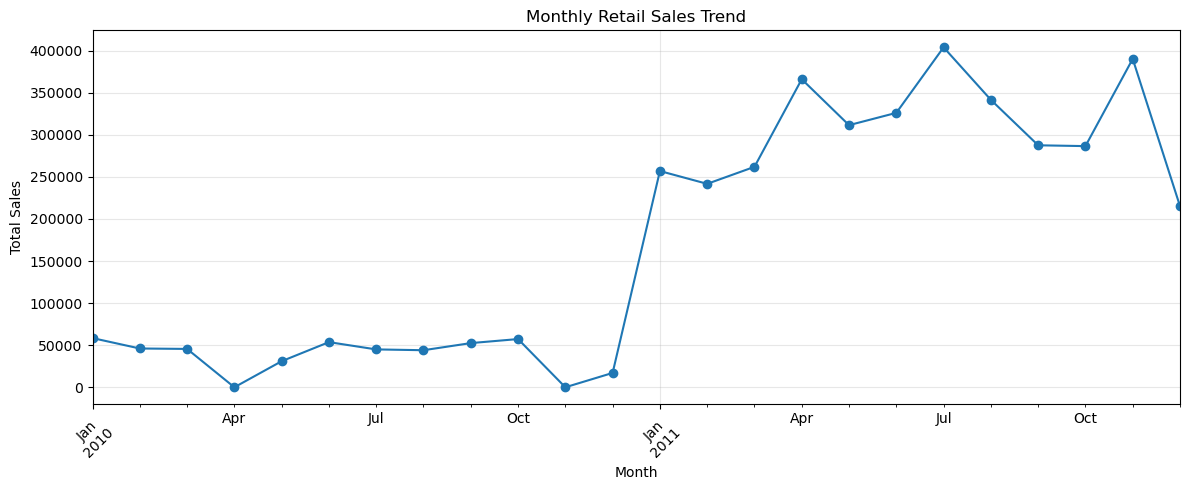

In [15]:
# Analyze monthly sales

if "InvoiceDate" in df_processed.columns and "TotalSales" in df_processed.columns:
    monthly_sales = (
        df_processed.dropna(subset=["InvoiceDate"])
        .set_index("InvoiceDate")["TotalSales"]
        .resample("MS")
        .sum()
    )

    plt.figure(figsize=(12, 5))
    monthly_sales.plot(marker="o")
    plt.title("Monthly Retail Sales Trend")
    plt.xlabel("Month")
    plt.ylabel("Total Sales")
    plt.xticks(rotation=45)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print("Required columns are missing. Check Step 5.")

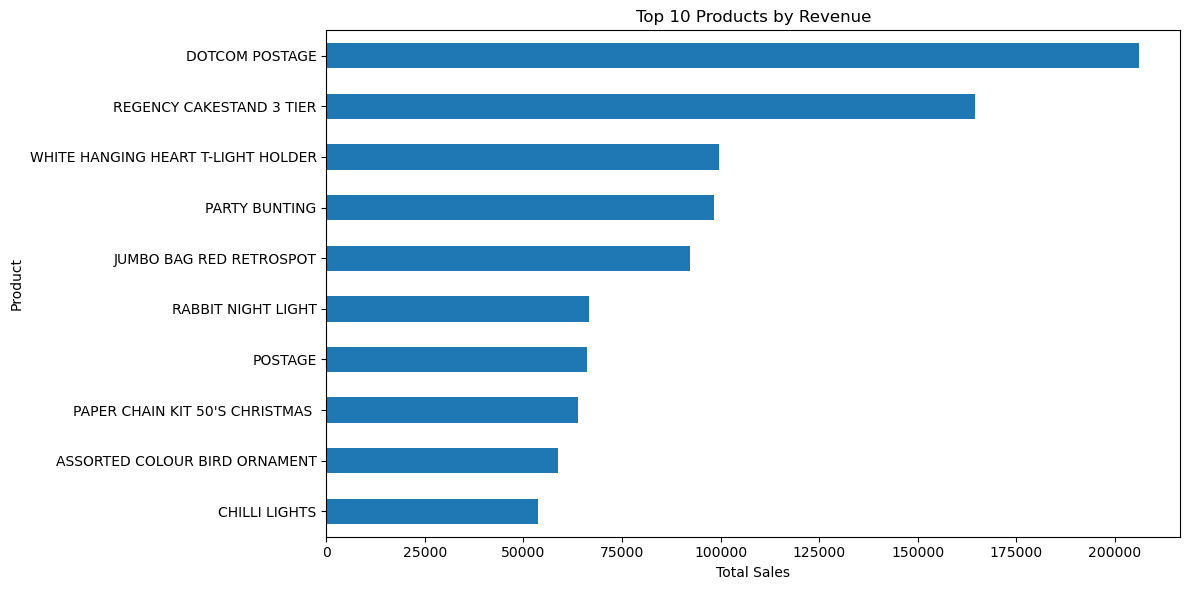

,Total Revenue
Description,
DOTCOM POSTAGE,206245.48
REGENCY CAKESTAND 3 TIER,164459.49
WHITE HANGING HEART T-LIGHT HOLDER,99612.42
PARTY BUNTING,98243.88
JUMBO BAG RED RETROSPOT,92175.79
RABBIT NIGHT LIGHT,66661.63
POSTAGE,66230.64
PAPER CHAIN KIT 50'S CHRISTMAS,63715.24
ASSORTED COLOUR BIRD ORNAMENT,58792.42


In [16]:
# Identify top products by revenue

if all(col in df_processed.columns for col in ["Description", "TotalSales"]):
    product_sales = (
        df_processed.dropna(subset=["Description"])
        .groupby("Description")["TotalSales"]
        .sum()
        .sort_values(ascending=False)
        .head(10)
    )

    plt.figure(figsize=(12, 6))
    product_sales.sort_values().plot(kind="barh")
    plt.title("Top 10 Products by Revenue")
    plt.xlabel("Total Sales")
    plt.ylabel("Product")
    plt.tight_layout()
    plt.show()

    display(product_sales.to_frame("Total Revenue"))
else:
    print("Description or TotalSales column is missing.")

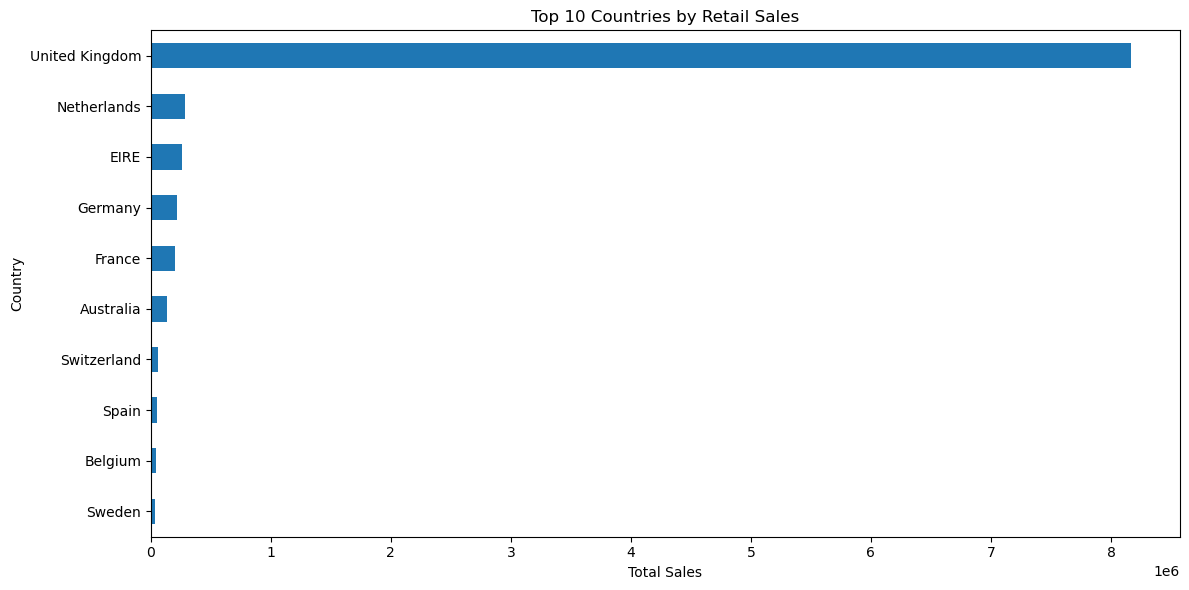

,Total Sales
Country,
United Kingdom,8167128.184
Netherlands,284661.540
EIRE,262993.380
Germany,221509.470
France,197317.110
Australia,137009.770
Switzerland,56363.050
Spain,54756.030
Belgium,40910.960


In [19]:
# Analyze sales by country

if all(col in df_processed.columns for col in ["Country", "TotalSales"]):
    country_sales = (
        df_processed.groupby("Country")["TotalSales"]
        .sum()
        .sort_values(ascending=False)
        .head(10)
    )

    plt.figure(figsize=(12, 6))
    country_sales.sort_values().plot(kind="barh")
    plt.title("Top 10 Countries by Retail Sales")
    plt.xlabel("Total Sales")
    plt.ylabel("Country")
    plt.tight_layout()
    plt.show()

    display(country_sales.to_frame("Total Sales"))
else:
    print("Country or TotalSales column is missing.")

### Exploratory Data Analysis Findings

The visualizations provide an overview of monthly sales trends, top-performing products, and country-wise revenue.

The monthly trend helps identify periods of higher or lower sales. The product analysis highlights products contributing the most revenue, while the country analysis identifies important geographical markets.

Specific findings and numerical values will be documented after reviewing the actual outputs generated by the notebook.

## 5. Customer Segmentation Using K-Means Clustering

Customer segmentation is an unsupervised machine learning technique used to group customers based on similar purchasing behavior.

In this project, customers will be analyzed using:
- Total spending
- Total quantity purchased
- Number of unique invoices

The K-Means algorithm will be applied to these features to identify customer groups. Feature scaling will be performed because the variables may have different ranges.

In [20]:
# Prepare customer-level features

required_columns = [
    "CustomerID",
    "TotalSales",
    "Quantity",
    "InvoiceNo"
]

if all(col in df_processed.columns for col in required_columns):

    customer_df = df_processed.dropna(
        subset=["CustomerID"]
    ).copy()

    customer_features = customer_df.groupby("CustomerID").agg(
        TotalSpending=("TotalSales", "sum"),
        TotalQuantity=("Quantity", "sum"),
        NumberOfInvoices=("InvoiceNo", "nunique")
    ).reset_index()

    print("Customer-level dataset created.")
    print("Number of customers:", len(customer_features))

    display(customer_features.head())

else:
    print("Some required columns are missing.")
    print("Available columns:", df_processed.columns.tolist())

Customer-level dataset created.
Number of customers: 4372


,CustomerID,TotalSpending,TotalQuantity,NumberOfInvoices
0,12346.0,0.00,0,2
1,12347.0,4310.00,2458,7
2,12348.0,1797.24,2341,4
3,12349.0,1757.55,631,1
4,12350.0,334.40,197,1


In [21]:
from sklearn.preprocessing import StandardScaler

# Select features for clustering

feature_columns = [
    "TotalSpending",
    "TotalQuantity",
    "NumberOfInvoices"
]

customer_model_data = customer_features[
    feature_columns
].replace([np.inf, -np.inf], np.nan).dropna()

# Keep only customers with positive spending and quantity
customer_model_data = customer_model_data[
    (customer_model_data["TotalSpending"] > 0) &
    (customer_model_data["TotalQuantity"] > 0) &
    (customer_model_data["NumberOfInvoices"] > 0)
]

print("Customers available for clustering:", len(customer_model_data))

scaler = StandardScaler()
X_scaled = scaler.fit_transform(customer_model_data)

print("Features scaled successfully.")

Customers available for clustering: 4315
Features scaled successfully.


In [23]:
# Apply K-Means clustering

from sklearn.cluster import KMeans
import os

# Avoid the Windows CPU detection warning
os.environ["LOKY_MAX_CPU_COUNT"] = "4"

if len(customer_model_data) >= 3:

    kmeans = KMeans(
        n_clusters=3,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(X_scaled)

    customer_segments = customer_model_data.copy()
    customer_segments["Cluster"] = cluster_labels

    print("K-Means clustering completed successfully!")
    print("\nCustomers in each cluster:")
    print(customer_segments["Cluster"].value_counts().sort_index())

    display(customer_segments.head())

else:
    print("Not enough customers for three clusters.")

K-Means clustering completed successfully!

Customers in each cluster:
Cluster
0    4269
1       5
2      41
Name: count, dtype: int64


,TotalSpending,TotalQuantity,NumberOfInvoices,Cluster
1,4310.00,2458,7,0
2,1797.24,2341,4,0
3,1757.55,631,1,0
4,334.40,197,1,0
5,1545.41,470,11,0


### 5.1 Visualization of Customer Segments

In this section, customer groups identified by the K-Means algorithm are visualized using a scatter plot. The plot compares total customer spending with total quantity purchased and uses different colors to represent the clusters.

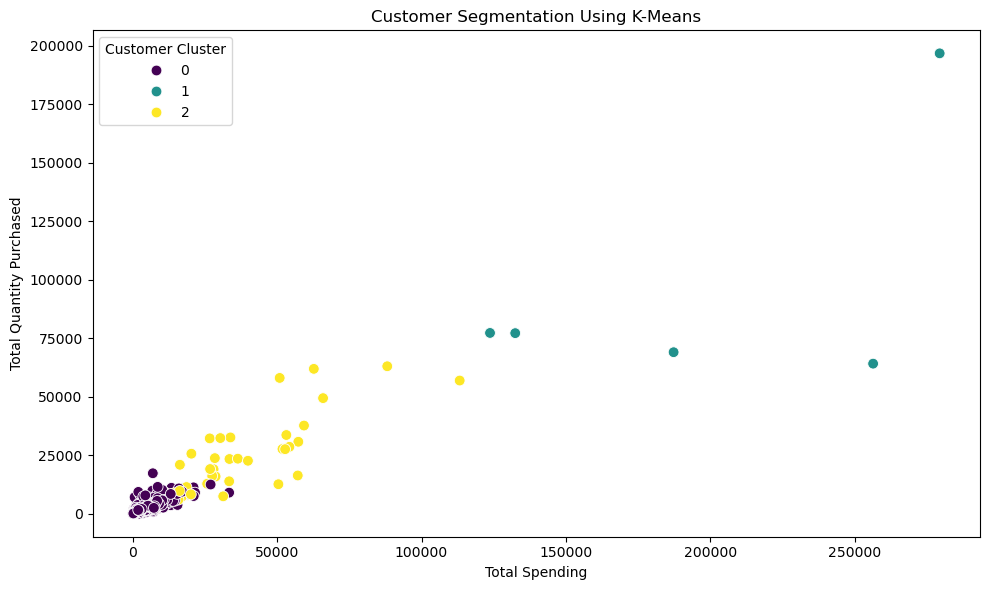

In [24]:
# Visualize customer segments

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=customer_segments,
    x="TotalSpending",
    y="TotalQuantity",
    hue="Cluster",
    palette="viridis",
    s=60
)

plt.title("Customer Segmentation Using K-Means")
plt.xlabel("Total Spending")
plt.ylabel("Total Quantity Purchased")
plt.legend(title="Customer Cluster")
plt.tight_layout()

plt.savefig("task6_customer_segmentation.png", dpi=300)
plt.show()

In [25]:
# Evaluate clustering using Silhouette Score

from sklearn.metrics import silhouette_score

if customer_segments["Cluster"].nunique() > 1:

    score = silhouette_score(
        X_scaled,
        customer_segments["Cluster"]
    )

    print("Silhouette Score:", round(score, 4))

else:
    print("Silhouette Score cannot be calculated because only one cluster exists.")

Silhouette Score: 0.9233


### Customer Segmentation Findings

The K-Means algorithm grouped customers according to their total spending, total quantity purchased, and invoice frequency.

The scatter plot visualizes the customer clusters, while the Silhouette Score provides a measure of cluster separation and cohesion.

The final interpretation of customer groups and business recommendations will be based on the observed cluster profiles and evaluation results.

## 6. Supervised Machine Learning: Sales Prediction

In this step, a supervised machine learning regression model is developed to predict transaction-line sales.

The TotalSales column is used as the target variable. Invoice date features are used as predictors where available.

The dataset is divided into training and testing sets. Model performance is evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the R² score.

In [26]:
# Prepare data for sales prediction

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

feature_columns = [
    "InvoiceMonth",
    "InvoiceDay",
    "InvoiceWeekday",
    "InvoiceHour"
]

available_features = [
    col for col in feature_columns
    if col in df_processed.columns
]

model_df = df_processed[
    available_features + ["TotalSales"]
].copy()

model_df = model_df.replace([np.inf, -np.inf], np.nan)
model_df = model_df.dropna()

print("Available features:", available_features)
print("Rows available for modeling:", len(model_df))
display(model_df.head())

Available features: ['InvoiceMonth', 'InvoiceDay', 'InvoiceWeekday', 'InvoiceHour']
Rows available for modeling: 230656


,InvoiceMonth,InvoiceDay,InvoiceWeekday,InvoiceHour,TotalSales
0,1.0,12.0,1.0,8.0,15.30
1,1.0,12.0,1.0,8.0,20.34
2,1.0,12.0,1.0,8.0,22.00
3,1.0,12.0,1.0,8.0,20.34
4,1.0,12.0,1.0,8.0,20.34


In [27]:
# Split data into features and target

if len(available_features) > 0 and len(model_df) >= 10:

    X = model_df[available_features]
    y = model_df["TotalSales"]

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42
    )

    print("Training rows:", len(X_train))
    print("Testing rows:", len(X_test))

else:
    print("Insufficient data or no suitable features are available.")

Training rows: 184524
Testing rows: 46132


In [28]:
# Train a Random Forest regression model

if len(available_features) > 0 and len(model_df) >= 10:

    model = RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=1
    )

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    print("Model training and prediction completed!")

else:
    print("Run the data preparation steps and check the available features.")

Model training and prediction completed!


In [29]:
# Evaluate regression performance

if "y_pred" in globals():

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    regression_results = pd.DataFrame({
        "Metric": ["MAE", "RMSE", "R2 Score"],
        "Value": [mae, rmse, r2]
    })

    display(regression_results)

    regression_results.to_csv(
        "task6_regression_results.csv",
        index=False
    )

else:
    print("Model predictions are unavailable. Run the training cell first.")

,Metric,Value
0,MAE,19.682904
1,RMSE,131.349440
2,R2 Score,0.036063


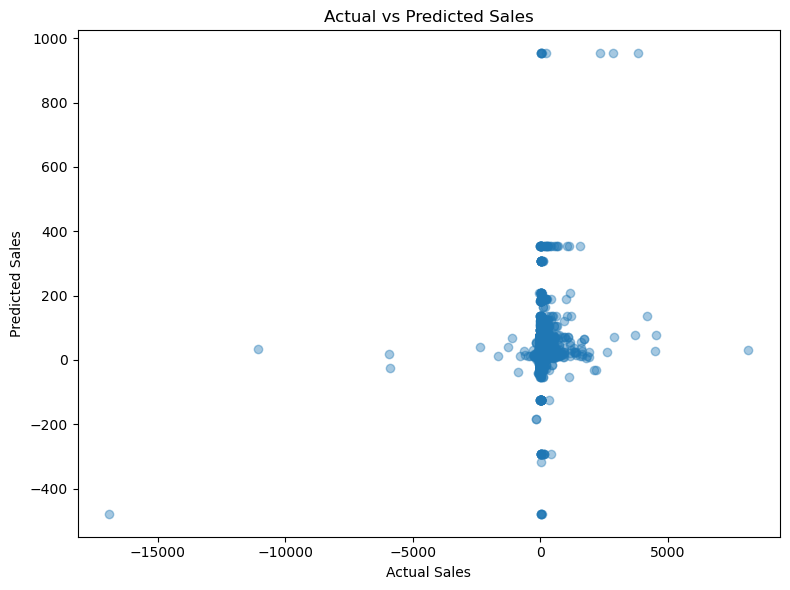

In [30]:
# Compare actual and predicted sales

if "y_pred" in globals():

    plt.figure(figsize=(8, 6))

    plt.scatter(y_test, y_pred, alpha=0.4)

    plt.title("Actual vs Predicted Sales")
    plt.xlabel("Actual Sales")
    plt.ylabel("Predicted Sales")
    plt.tight_layout()

    plt.savefig("task6_actual_vs_predicted.png", dpi=300)
    plt.show()

else:
    print("Run the model training cell first.")

### Sales Prediction Findings

A Random Forest regression model was trained to predict transaction-line sales using available invoice date features.

The model was evaluated using MAE, RMSE, and R². These metrics help assess prediction errors and the model's ability to explain variation in the target variable.

The results should be interpreted with caution because invoice date features alone may not capture important factors such as product prices, quantities, discounts, or customer purchasing behavior.

## 7. Business Insights and Recommendations

In this section, the results of exploratory data analysis, customer segmentation, and sales prediction are summarized.

The objective is to translate analytical findings into practical recommendations that can help a retail business improve customer engagement, sales planning, and marketing decisions.

In [32]:
# Summarize customer segments

segment_summary = customer_segments.groupby("Cluster").agg(
    NumberOfCustomers=("TotalSpending", "size"),
    AverageSpending=("TotalSpending", "mean"),
    AverageQuantity=("TotalQuantity", "mean"),
    AverageInvoices=("NumberOfInvoices", "mean")
).round(2)

print("Customer Segment Summary:")
display(segment_summary)

Customer Segment Summary:


,NumberOfCustomers,AverageSpending,AverageQuantity,AverageInvoices
Cluster,,,,
0,4269,1368.20,809.90,4.50
1,5,195886.77,96849.40,93.60
2,41,35866.13,22934.39,59.27


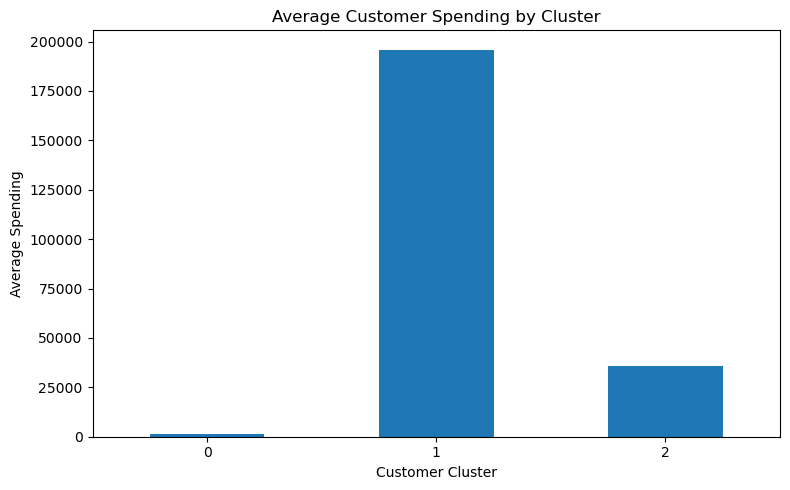

In [33]:
# Compare average spending across customer clusters

plt.figure(figsize=(8, 5))

segment_summary["AverageSpending"].plot(kind="bar")

plt.title("Average Customer Spending by Cluster")
plt.xlabel("Customer Cluster")
plt.ylabel("Average Spending")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("task6_segment_spending.png", dpi=300)
plt.show()

In [34]:
# Save customer segmentation results

customer_segments.to_csv(
    "task6_customer_segments.csv",
    index=False
)

segment_summary.to_csv(
    "task6_segment_summary.csv"
)

print("Customer segmentation files saved successfully!")

Customer segmentation files saved successfully!


In [35]:
# Save a summary of the processed dataset

cleaning_summary = pd.DataFrame({
    "Metric": [
        "Original Rows",
        "Processed Rows",
        "Original Columns",
        "Processed Columns",
        "Missing Values in Processed Data",
        "Duplicate Rows in Processed Data"
    ],
    "Value": [
        len(df),
        len(df_processed),
        len(df.columns),
        len(df_processed.columns),
        int(df_processed.isnull().sum().sum()),
        int(df_processed.duplicated().sum())
    ]
})

display(cleaning_summary)

cleaning_summary.to_csv(
    "task6_cleaning_summary.csv",
    index=False
)

print("Cleaning summary saved successfully!")

,Metric,Value
0,Original Rows,536641
1,Processed Rows,536641
2,Original Columns,8
3,Processed Columns,14
4,Missing Values in Processed Data,1972401
5,Duplicate Rows in Processed Data,1


Cleaning summary saved successfully!


### Business Recommendations

The results of the retail sales analysis and customer segmentation can help support business decisions.

1. **Customer Retention:** Consider loyalty programs for customers who purchase frequently.
2. **Targeted Marketing:** Design campaigns based on the purchasing behavior of different customer segments.
3. **Sales Planning:** Use historical sales trends to support inventory and promotional planning.
4. **Product Strategy:** Analyze top-performing products to identify opportunities for product bundling and cross-selling.
5. **Model Improvement:** Test additional features and alternative models to improve sales predictions.

These recommendations should be refined using the actual analytical results and customer segment profiles.

## 8. Conclusion

This project applied a data science workflow to an online retail dataset. The workflow included data inspection, preprocessing, exploratory data analysis, feature engineering, customer segmentation, and baseline sales prediction.

K-Means clustering was used to group customers according to their spending, purchase quantity, and invoice frequency. A Random Forest regression model was developed to predict transaction-line sales using available date-related features.

The evaluation metrics and visualizations provide a basis for assessing model performance and understanding customer purchasing behavior. The findings can help guide customer engagement, sales planning, and marketing decisions.

### Limitations and Future Improvements

- Date-related features alone may not be sufficient for accurate sales prediction.
- Customer segments depend on the features and number of clusters selected.
- Further work can compare additional regression models and clustering configurations.
- Additional validation and more informative features may improve the reliability of the results.

## 9. Project Deliverables

The project generates the following outputs:

- Customer segmentation results
- Customer segment summary
- Data cleaning summary
- Regression evaluation metrics
- Sales trend visualizations
- Customer segmentation visualizations

These outputs support the final report and document the analytical workflow.

In [36]:
# Verify generated project files

import os

expected_files = [
    "task6_cleaning_summary.csv",
    "task6_regression_results.csv",
    "task6_customer_segments.csv",
    "task6_segment_summary.csv",
    "task6_customer_segmentation.png",
    "task6_segment_spending.png",
    "task6_actual_vs_predicted.png"
]

print("Project Output Verification\n")

for filename in expected_files:
    if os.path.exists(filename):
        print(f"[FOUND] {filename}")
    else:
        print(f"[NOT FOUND] {filename}")

Project Output Verification

[FOUND] task6_cleaning_summary.csv
[FOUND] task6_regression_results.csv
[FOUND] task6_customer_segments.csv
[FOUND] task6_segment_summary.csv
[FOUND] task6_customer_segmentation.png
[FOUND] task6_segment_spending.png
[FOUND] task6_actual_vs_predicted.png



# Week 6 Capstone Project Report

## Project Title
Retail Sales Analysis and Customer Segmentation Using Python

## 1. Project Overview
This project analyzes an online retail dataset to understand sales performance, identify customer purchasing patterns, and explore customer segmentation using machine learning.

## 2. Objectives
- Analyze and clean retail transaction data.
- Explore sales trends across time, products, and countries.
- Segment customers using the K-Means clustering algorithm.
- Build a baseline sales prediction model using Random Forest Regression.
- Generate actionable business insights from the analysis.

## 3. Tools and Technologies
- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- Jupyter Notebook

## 4. Dataset
The project uses the online_retail_cleaned.csv dataset. The analysis uses transaction details such as customer ID, invoice number, product description, quantity, unit price, invoice date, and country, where available.

## 5. Methodology
1. Load and inspect the dataset.
2. Check missing values, duplicates, and data types.
3. Prepare sales and date-related features.
4. Perform exploratory data analysis (EDA).
5. Apply K-Means clustering to customer-level features.
6. Train and evaluate a baseline Random Forest Regression model.
7. Export results and visualizations.


In [37]:

print("CAPSTONE PROJECT — RESULTS SUMMARY")
print("=" * 45)

print(f"Original dataset rows: {len(df):,}")
print(f"Processed dataset rows: {len(df_processed):,}")
print(f"Total sales value: {df_processed['TotalSales'].sum():,.2f}")

if "customer_segments" in globals():
    print(f"Customers segmented: {len(customer_segments):,}")
    print("\nCustomer Segment Summary:")
    display(segment_summary)

if "regression_results" in globals():
    print("\nSales Prediction Evaluation:")
    display(regression_results)
else:
    print("\nRegression results are not available yet.")


CAPSTONE PROJECT — RESULTS SUMMARY
Original dataset rows: 536,641
Processed dataset rows: 536,641
Total sales value: 9,726,006.95
Customers segmented: 4,315

Customer Segment Summary:


,NumberOfCustomers,AverageSpending,AverageQuantity,AverageInvoices
Cluster,,,,
0,4269,1368.20,809.90,4.50
1,5,195886.77,96849.40,93.60
2,41,35866.13,22934.39,59.27



Sales Prediction Evaluation:


,Metric,Value
0,MAE,19.682904
1,RMSE,131.349440
2,R2 Score,0.036063


In [38]:

# Step 14: Generate report findings from actual project results

total_sales = df_processed["TotalSales"].sum()
total_transactions = df_processed["InvoiceNo"].nunique()
total_customers = df_processed["CustomerID"].nunique()

print("PROJECT FINDINGS")
print("-" * 45)
print(f"Total sales value: {total_sales:,.2f}")
print(f"Unique invoices: {total_transactions:,}")
print(f"Unique customers in processed data: {total_customers:,}")

if "segment_summary" in globals():
    print("\nCUSTOMER SEGMENT INSIGHTS")
    display(segment_summary)

if "regression_results" in globals():
    print("\nSALES PREDICTION RESULTS")
    display(regression_results)

# Generate a text file for use in the final report
report_text = f"""
WEEK 6 CAPSTONE PROJECT: FINDINGS

Project: Retail Sales Analysis and Customer Segmentation Using Python

1. Dataset Analysis
The processed dataset contains {len(df_processed):,} rows.
The dataset contains {total_transactions:,} unique invoices.
There are {total_customers:,} unique customers with recorded customer IDs.
The total calculated sales value is {total_sales:,.2f}.

2. Customer Segmentation
K-Means clustering was used to group customers using total spending,
total quantity purchased, and number of invoices.
Refer to the exported segment summary for the actual cluster statistics.

3. Sales Prediction
A Random Forest Regression model was used as a baseline.
Use the recorded MAE, RMSE, and R2 Score to evaluate its performance.
Date-based features alone may not capture product, customer, or
promotional effects on sales.

4. Business Recommendations
- Use customer segments to guide targeted marketing campaigns.
- Investigate high-spending and frequent customers for retention strategies.
- Review product and country-level sales patterns to support planning.
- Improve prediction by testing additional features and time-based validation.

5. Limitations
Results depend on the quality and coverage of the supplied dataset.
Customer clustering depends on the selected features and number of clusters.
The regression model uses a limited set of date-related predictors.

6. Conclusion
This project combines data cleaning, exploratory analysis, customer
segmentation, and baseline regression in a single Python workflow.
The results can help explore customer behavior and retail sales patterns.
Further validation is needed before using the model for business decisions.
"""

with open("task6_report_findings.txt", "w", encoding="utf-8") as file:
    file.write(report_text)

print("\nReport findings saved to task6_report_findings.txt")


PROJECT FINDINGS
---------------------------------------------
Total sales value: 9,726,006.95
Unique invoices: 25,900
Unique customers in processed data: 4,372

CUSTOMER SEGMENT INSIGHTS


,NumberOfCustomers,AverageSpending,AverageQuantity,AverageInvoices
Cluster,,,,
0,4269,1368.20,809.90,4.50
1,5,195886.77,96849.40,93.60
2,41,35866.13,22934.39,59.27



SALES PREDICTION RESULTS


,Metric,Value
0,MAE,19.682904
1,RMSE,131.349440
2,R2 Score,0.036063



Report findings saved to task6_report_findings.txt


In [40]:

%pip install python-docx


Note: you may need to restart the kernel to use updated packages.


In [41]:

from docx import Document
from docx.shared import Inches, Pt
from docx.enum.text import WD_ALIGN_PARAGRAPH

print("python-docx installed successfully!")


python-docx installed successfully!


In [42]:

import os

deliverables = [
    "Task6_Integrative_Capstone_Report.docx",
    "task6_report_findings.txt",
    "task6_cleaning_summary.csv",
    "task6_regression_results.csv",
    "task6_customer_segments.csv",
    "task6_segment_summary.csv",
    "task6_customer_segmentation.png",
    "task6_segment_spending.png",
    "task6_actual_vs_predicted.png"
]

print("WEEK 6 CAPSTONE — FINAL FILE CHECK")
print("=" * 45)

for filename in deliverables:
    if os.path.exists(filename):
        size_kb = os.path.getsize(filename) / 1024
        print(f"[FOUND] {filename} ({size_kb:.1f} KB)")
    else:
        print(f"[MISSING] {filename}")


WEEK 6 CAPSTONE — FINAL FILE CHECK
[MISSING] Task6_Integrative_Capstone_Report.docx
[FOUND] task6_report_findings.txt (1.6 KB)
[FOUND] task6_cleaning_summary.csv (0.2 KB)
[FOUND] task6_regression_results.csv (0.1 KB)
[FOUND] task6_customer_segments.csv (75.1 KB)
[FOUND] task6_segment_summary.csv (0.2 KB)
[FOUND] task6_customer_segmentation.png (157.2 KB)
[FOUND] task6_segment_spending.png (83.6 KB)
[FOUND] task6_actual_vs_predicted.png (151.6 KB)
